# Possession pipeline — summary and run

This notebook is the executable overview. The detailed reasoning is kept in the numbered guides next to it.

## What we do

1. Load and audit the supplied ATD, Smart Tagging, and metadata tables.
2. Apply the published graded-frame mask; output `X` outside the two graded intervals.
3. Build pitch distances, margins, zones, pressure, movement, reachability, and reception features.
4. Identify dead-ball context, comfortable-control anchors, flight, contest, occlusion, and reception scenarios.
5. Resolve bounded trajectories using previous anchors and later controlled reception evidence.
6. Protect strong `D` and `X` evidence, write H/A/D/X labels, and evaluate Macro-F1 and Spell-F1.

This is an offline trajectory-classification pipeline. A scenario may look forward to the later receiver, but the current H/A label is preserved until controlled reception evidence confirms a switch. The rule hierarchy is documented in `3b_RULE_BOOK.md`; Viterbi, HMM, and HSMM are registered alternative decoders rather than methods blindly stacked together.

## Modular implementation

The notebook calls a thin canonical runner. The runner performs three stages:

1. build the complete feature/evidence table;
2. detect scenario evidence;
3. pass that evidence to one explicitly selected model.

The model selector is deliberately separate from the feature and scenario functions. This notebook runs one selected model and writes its frame-aligned submission; notebook 08 owns the multi-model leaderboard.

In [1]:
# Setup: choose one model and keep paths in one place.
from pathlib import Path
import sys

ROOT = Path.cwd()
if not (ROOT / "possession").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from possession.baseline_pipeline import ClosestTeamRuleModel
from possession.pipeline import run_decision_pipeline, select_model

MODEL_NAME = "aligned_physics_veto"
MODEL_SPEC = select_model(MODEL_NAME)
RESULTS = ROOT / "evaluation" / "results"
OUTPUT = RESULTS / f"selected_{MODEL_NAME}.csv"
print("project root:", ROOT)
print("selected model:", MODEL_SPEC)
print("output:", OUTPUT)


project root: /Users/luke/Desktop/barca-hack-repo-staging
selected model: PipelineSpec(name='aligned_physics_veto', anchor_source='selected_anchor_team', use_smart_set_piece=True, use_dead_ball_boundary=True, use_literal_out_of_bounds=False, transition_rule='aligned_reception', use_physics_veto=True, decoder='none', protect_dead_ball=True, protect_outside_graded=True)
output: /Users/luke/Desktop/barca-hack-repo-staging/evaluation/results/selected_aligned_physics_veto.csv


## Run one selected model

The public runner now makes the composition explicit: features → scenarios → selected model.

In [2]:
# Build evidence, detect scenarios, apply the selected model, and store one result.
data_model = ClosestTeamRuleModel()
features, labels = run_decision_pipeline(
    model=data_model,
    model_name=MODEL_NAME,
)
OUTPUT.parent.mkdir(parents=True, exist_ok=True)
data_model.write_submission(OUTPUT, labels)
print("frames:", len(features))
print("labels:", dict(zip(*__import__("numpy").unique(labels, return_counts=True))))
print("stored:", OUTPUT)
confidence_columns = [
    column for column in [
        "scenario_confidence", "scenario_margin",
        "selected_anchor_confidence", "controlled_reception_signal_score",
    ] if column in features.columns
]
print("confidence signals:", confidence_columns)
if confidence_columns:
    display(features[["frame", *confidence_columns]].dropna(how="all").head(10))


frames: 199319
labels: {np.str_('A'): np.int64(29402), np.str_('D'): np.int64(91198), np.str_('H'): np.int64(38257), np.str_('X'): np.int64(40462)}
stored: /Users/luke/Desktop/barca-hack-repo-staging/evaluation/results/selected_aligned_physics_veto.csv
confidence signals: ['scenario_confidence', 'scenario_margin', 'selected_anchor_confidence', 'controlled_reception_signal_score']


,frame,scenario_confidence,scenario_margin,selected_anchor_confidence,controlled_reception_signal_score
0,0,1.0,0.75,0.0,NaN
1,1,1.0,0.75,0.0,NaN
2,2,1.0,0.75,0.0,NaN
3,3,1.0,0.75,0.0,NaN
4,4,1.0,0.75,0.0,NaN
5,5,1.0,0.75,0.0,NaN
6,6,1.0,0.75,0.0,NaN
7,7,1.0,0.75,0.0,NaN
8,8,1.0,0.75,0.0,NaN
9,9,1.0,0.75,0.0,NaN


## Inspect one internal ball gap

This diagnostic plot is separate from submission labelling. Solid blue segments are observed ball coordinates; the orange dotted bridge is the missing interval; the purple dashed path is nearest-player geometry; red and green dots are player positions at one reference frame.

Smart Tagging is shown as a context clue only. It can cover preparation, flight, and reception together, so we inspect it selectively rather than copying its team label to every frame. ATD coordinates are normalised in the data and converted here to the supplied pitch in metres: x=0..105.3 and y=0..68.


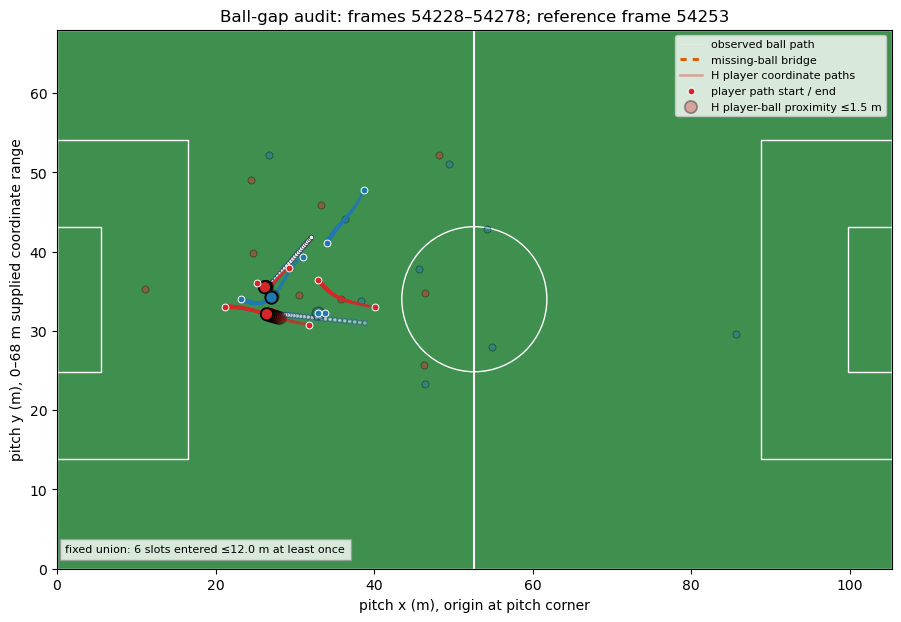

In [3]:
# Diagnostic only: visualise observed, missing, and nearest-player geometry.
from possession.baseline_pipeline import ClosestTeamRuleModel, slot_team_map
from possession.pipeline import build_evidence_table as build_engineered_features
from possession.calculations.plotting import plot_trajectory_window, select_representative_ball_gap
from games import asset_paths
from possession.temporal_rules import load_rules
import matplotlib.pyplot as plt

rules = load_rules()
model = ClosestTeamRuleModel()
plot_features = build_engineered_features(model=model, rules=rules)
gap = select_representative_ball_gap(plot_features)
if gap is None:
    print('No internal ball-coordinate gap was found.')
else:
    gap_start, gap_end = gap
    team_by_slot = slot_team_map(asset_paths(model.game, model.data_dir, source='tactical')['atd_meta'])
    fig, ax = plot_trajectory_window(plot_features, max(0, gap_start - 25), gap_end + 25, team_by_slot=team_by_slot, reference_frame=(gap_start + gap_end) // 2)
    plt.show()


## Read the reasoning around the run

- [01 — EDA](./01_eda.ipynb)
- [02 — Feature engineering](./02_feature_engineering.ipynb)
- [03 — Scenario engineering](./03_scenario_engineering.ipynb)
- [05 — Anchors](./05_anchors_rulebook.ipynb)
- [06 — Transition markers](./06_transition_markers.ipynb)
- [07 — Viterbi model](./07_viterbi_model.ipynb)
- [09 — Experimental results](./09_experimental_results.ipynb)